# Computational Methods — Text as Data
## Getting started with text representations

In this class, we turn raw text into numbers that a computer can analyse. We work with a large collection of **tweets by US politicians**, labelled by party (Democrat or Republican).

We will learn how to:

* **preprocess** text with `spaCy` (tokens, lemmas, parts of speech, stop words);
* build **sparse representations**: word counts, n-grams and TF-IDF weights;
* use **character n-grams**, which work without any tokenization;
* train **word embeddings** (`Word2Vec`) and load **pre-trained embeddings** (GloVe);
* build **document representations** from word embeddings, and see where they fail;
* use **Transformer-based sentence embeddings** to compare the meaning of whole sentences;
* compare all of these representations on the same task, in the exercises at the end.

### Before you start

* **Save your own copy first.** Go to **File → Save a copy in Drive**. A new tab opens with your own copy. Work in that tab; edits to the original are not saved.
* **The page loads itself.** There is nothing to download or upload. The cells below download the practice dataset from Hugging Face for you; you just need to be online. If the connection is slow, a backup copy of the page is built in.

# WARNING:
- `gensim` currently uses a lower version of `numpy`
- to make the notebook work, we need to check for import, then restart.

The following cell should do that. After it has completed, you should be able to run the entire notebook.

In [ ]:
try:
  import gensim
except ImportError:
  !pip install gensim
  import os
  print('Stopping RUNTIME! Please click "Runtim" > Run all" again.')
  os.kill(os.getpid(), 9)

# Preprocessing

Let's first look at different levels of linguistic analysis, which will make preprocessing easier. We will use the `spacy` library for a lot of the analyses. First, we need to import and  load the appropriate model (here, the one for English):

In [ ]:
import spacy

# check whether model exists, otherwise download
try:
    nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
except OSError:
    spacy.cli.download('en_core_web_sm')
    nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])


### Usage:

We can now call `nlp()` as a function on any text. By default, it will perform a number of analyses:

* Tokenization – Splits text into individual words, punctuation, and symbols
(tokens).

* Sentence splitting – Divides text into separate sentences.

* Lemmatization – Reduces words to their base or dictionary form (lemma).

* Part of speech tagging – Identifies the grammatical role of each word (e.g., noun, verb).

* Dependency parsing – Analyzes grammatical relationships between words in a sentence.

* Named entity recognition – Detects and classifies proper names (e.g., people, places, organizations).

* To speed up analysis, we can disable some of these analyses if we do not need it:
```
nlp = spacy.load('en_core_web_sm', disable=['tokenizer', 'tagger', 'parser', 'ner'])
```


The result is an iterator over the sentences (if called on a text), or tokens (if called on a sentence). Each token has a range of properties see [here](https://spacy.io/api/token#attributes). We will use a few of them in the following:

- `text`: the actual word
- `lemma_`: the dictionary entry of a word
- `pos_`: the part of speech
- `dep`: dependency relation
- `is_punct`: check whether word is punctuation
- `is_stop`: check whether word is a stop word

Let's first get some data:

In [ ]:
# import df
from datasets import load_dataset
import pandas as pd

dataset = load_dataset("Jacobvs/PoliticalTweets")

# Inspect available splits
print(dataset)

# Load the main split into a pandas DataFrame
split_name = list(dataset.keys())[0]
df = dataset[split_name].to_pandas()

print(f"Number of tweets: {len(df):,}")
print("\nColumns:")
print(df.columns.tolist())

df.head()

README.md:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

formatted_data.parquet: reconstructing file:   0%|          |  0.00B / 26.6MB            

formatted_data.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/190491 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['index', 'date', 'id', 'username', 'text', 'party', 'labels'],
        num_rows: 190491
    })
})
Number of tweets: 190,491

Columns:
['index', 'date', 'id', 'username', 'text', 'party', 'labels']


,index,date,id,username,text,party,labels
0,0,2021-10-13 19:47:44,1448374915636383745,SenatorHassan,Happy th birthday to the @USNavy! The strength...,Democrat,1
1,1,2021-06-30 14:53:13,1410250073003462656,SenatorMenendez,The greatest generation's investment in infras...,Democrat,1
2,2,2021-08-08 01:11:29,1424176405881966599,SenBillCassidy,"Thanks to @SenTedCruz and @SenatorWarnock, th...",Republican,0
3,3,2021-04-14 14:02:49,1382333523567185921,SenBlumenthal,/ To get lasting change we cant just lock up t...,Democrat,1
4,4,2021-12-11 16:06:38,1469700160934621188,SenatorBraun,Today were celebrating years of the Hoosier st...,Republican,0


In [ ]:
# Let's check it out!
TEXT_COL = text_candidates[0]
PARTY_COL = party_candidates[0]

# Tweets per party
print(df[PARTY_COL].value_counts(dropna=False))

# A few examples from each party
for party, group in df.groupby(PARTY_COL):
    print(f"\n{'=' * 60}\nParty: {party}")
    for tweet in group[TEXT_COL].dropna().head(3):
        print("-", tweet)

party
Democrat      97901
Republican    92590
Name: count, dtype: int64

Party: Democrat
- Happy th birthday to the @USNavy! The strength, dedication, and skill of our Sailors including those at Portsmouth Naval Shipyard help keep this country safe, secure, and free. Today we recognize and celebrate their incredible service. #246NavyBirthday https://t.co/GuHEDMApke
- The greatest generation's investment in infrastructure made us the envy of the world. But now we've gone almost an entire lifetime without making any significant investments in the NEXT generation of American infrastructure. It's time for that to change. https://t.co/brikl79Kgp
- / To get lasting change we cant just lock up those convicted of these crimes, but must also work to combat bias and  bigotry. The NO HATE Act would allow courts to implement alternative sentencingrequiring people to do educational training/community service to counter their hate.

Party: Republican
- Thanks to @SenTedCruz and  @SenatorWarnock, the

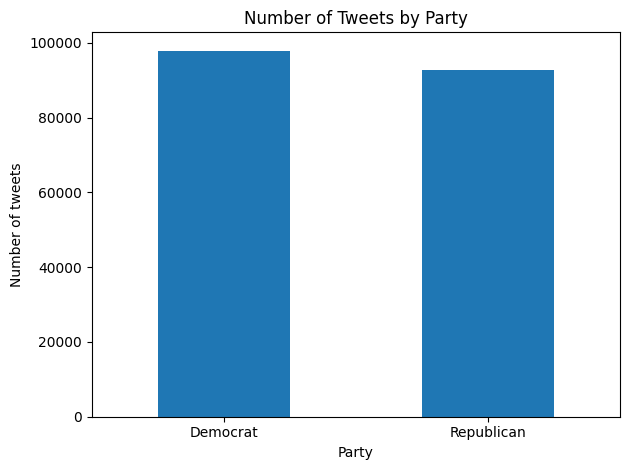

In [ ]:
import matplotlib.pyplot as plt

df[PARTY_COL].value_counts().plot(kind="bar")
plt.title("Number of Tweets by Party")
plt.xlabel("Party")
plt.ylabel("Number of tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
documents = df.text[:1000].tolist()
len(documents)

1000

In [ ]:
# preprocess all documents – this can take some time now, but will make the next steps faster
documents_p = list(nlp.pipe(documents))

print(documents[:2])

['Happy th birthday to the @USNavy! The strength, dedication, and skill of our Sailors including those at Portsmouth Naval Shipyard help keep this country safe, secure, and free. Today we recognize and celebrate their incredible service. #246NavyBirthday https://t.co/GuHEDMApke', "The greatest generation's investment in infrastructure made us the envy of the world. But now we've gone almost an entire lifetime without making any significant investments in the NEXT generation of American infrastructure. It's time for that to change. https://t.co/brikl79Kgp"]


## Tokenization
Before we do anything, we need to insert spaces into the data. Yes, here, they are already inserted, but we still need to turn the string into a list. (In other data sets, `spacy` will figure out where to insert spaces).

In [ ]:
# this creates a list of list of tokens (one per sentence)
tokens = [
    [token.text for token in sentence]
    for sentence in documents_p
]

print(tokens[:3])

[['Happy', 'th', 'birthday', 'to', 'the', '@USNavy', '!', 'The', 'strength', ',', 'dedication', ',', 'and', 'skill', 'of', 'our', 'Sailors', 'including', 'those', 'at', 'Portsmouth', 'Naval', 'Shipyard', 'help', 'keep', 'this', 'country', 'safe', ',', 'secure', ',', 'and', 'free', '.', 'Today', 'we', 'recognize', 'and', 'celebrate', 'their', 'incredible', 'service', '.', '#', '246NavyBirthday', 'https://t.co/GuHEDMApke'], ['The', 'greatest', 'generation', "'s", 'investment', 'in', 'infrastructure', 'made', 'us', 'the', 'envy', 'of', 'the', 'world', '.', 'But', 'now', 'we', "'ve", 'gone', 'almost', 'an', 'entire', 'lifetime', 'without', 'making', 'any', 'significant', 'investments', 'in', 'the', 'NEXT', 'generation', 'of', 'American', 'infrastructure', '.', 'It', "'s", 'time', 'for', 'that', 'to', 'change', '.', 'https://t.co/brikl79Kgp'], ['Thanks', 'to', '@SenTedCruz', 'and', ' ', '@SenatorWarnock', ',', 'the', 'Infrastructure', 'Investment', 'and', 'Jobs', 'Act', 'authorizes', 'the',

## Lemmatization
We want to get the dictionary form of each word, to reduce variation.

In [ ]:
lemmas = [
    [token.lemma_ for token in sentence]
    for sentence in documents_p
]

# let's compare the two versions
print(tokens[0])
print()
print(lemmas[0])

['Happy', 'th', 'birthday', 'to', 'the', '@USNavy', '!', 'The', 'strength', ',', 'dedication', ',', 'and', 'skill', 'of', 'our', 'Sailors', 'including', 'those', 'at', 'Portsmouth', 'Naval', 'Shipyard', 'help', 'keep', 'this', 'country', 'safe', ',', 'secure', ',', 'and', 'free', '.', 'Today', 'we', 'recognize', 'and', 'celebrate', 'their', 'incredible', 'service', '.', '#', '246NavyBirthday', 'https://t.co/GuHEDMApke']

['happy', 'th', 'birthday', 'to', 'the', '@USNavy', '!', 'the', 'strength', ',', 'dedication', ',', 'and', 'skill', 'of', 'our', 'sailor', 'include', 'those', 'at', 'Portsmouth', 'Naval', 'Shipyard', 'help', 'keep', 'this', 'country', 'safe', ',', 'secure', ',', 'and', 'free', '.', 'today', 'we', 'recognize', 'and', 'celebrate', 'their', 'incredible', 'service', '.', '#', '246navybirthday', 'https://t.co/GuHEDMApke']


# Representing Text

## Discrete Sparse Representations

We can now turn our documents into a data matrix of $n$ reviews and $m$ n-grams.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
small_vectorizer = CountVectorizer()

# small sample of 2 documents
sentences_2 = documents[:2]

X1 = small_vectorizer.fit_transform(sentences_2)


`CountVectorizer` does everything for us under the hood: collect counts, create an inverted index, and then some.
The main result is a *sparse count matrix*:

In [ ]:
# sparse indexed representation
print(X1)

# dense representation
print(X1.todense())

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 73 stored elements and shape (2, 67)>
  Coords	Values
  (0, 23)	1
  (0, 52)	1
  (0, 7)	1
  (0, 59)	1
  (0, 54)	2
  (0, 62)	1
  (0, 51)	1
  (0, 14)	1
  (0, 4)	3
  (0, 50)	1
  (0, 40)	1
  (0, 41)	1
  (0, 45)	1
  (0, 27)	1
  (0, 57)	1
  (0, 6)	1
  (0, 42)	1
  (0, 37)	1
  (0, 48)	1
  (0, 24)	1
  (0, 33)	1
  (0, 56)	1
  (0, 13)	1
  (0, 44)	1
  (0, 46)	1
  :	:
  (1, 35)	1
  (1, 61)	1
  (1, 16)	1
  (1, 66)	1
  (1, 9)	1
  (1, 39)	1
  (1, 63)	1
  (1, 20)	1
  (1, 1)	1
  (1, 3)	1
  (1, 15)	1
  (1, 34)	1
  (1, 65)	1
  (1, 36)	1
  (1, 5)	1
  (1, 49)	1
  (1, 31)	1
  (1, 38)	1
  (1, 2)	1
  (1, 32)	1
  (1, 58)	1
  (1, 17)	1
  (1, 53)	1
  (1, 11)	1
  (1, 8)	1
[[1 0 0 0 3 0 1 1 0 0 1 0 1 1 1 0 0 0 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0 1 0 0
  0 1 0 0 1 1 1 1 1 1 1 1 1 0 1 1 1 0 2 1 1 1 0 1 1 0 1 0 1 0 0]
 [0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 0 2 1 1 0 0 0 1 2 0 0 2 1 1 1 0 1 1
  1 0 1 1 2 0 0 0 0 0 0 0 0 1 0 0 0 1 4 0 0 0 1 1 0 1 0 1 1 1 1]]


We can access the mapping from vector position to feature names via `get_feature_names_out()`:

In [ ]:
print(small_vectorizer.get_feature_names_out())

['246navybirthday' 'almost' 'american' 'an' 'and' 'any' 'at' 'birthday'
 'brikl79kgp' 'but' 'celebrate' 'change' 'co' 'country' 'dedication'
 'entire' 'envy' 'for' 'free' 'generation' 'gone' 'greatest' 'guhedmapke'
 'happy' 'help' 'https' 'in' 'including' 'incredible' 'infrastructure'
 'investment' 'investments' 'it' 'keep' 'lifetime' 'made' 'making' 'naval'
 'next' 'now' 'of' 'our' 'portsmouth' 'recognize' 'safe' 'sailors'
 'secure' 'service' 'shipyard' 'significant' 'skill' 'strength' 'th'
 'that' 'the' 'their' 'this' 'those' 'time' 'to' 'today' 'us' 'usnavy'
 've' 'we' 'without' 'world']


The inverse (the mapping from feature names to vector positions) is encoded as a list in `vocabulary_`:

In [ ]:
print(small_vectorizer.vocabulary_)

{'happy': 23, 'th': 52, 'birthday': 7, 'to': 59, 'the': 54, 'usnavy': 62, 'strength': 51, 'dedication': 14, 'and': 4, 'skill': 50, 'of': 40, 'our': 41, 'sailors': 45, 'including': 27, 'those': 57, 'at': 6, 'portsmouth': 42, 'naval': 37, 'shipyard': 48, 'help': 24, 'keep': 33, 'this': 56, 'country': 13, 'safe': 44, 'secure': 46, 'free': 18, 'today': 60, 'we': 64, 'recognize': 43, 'celebrate': 10, 'their': 55, 'incredible': 28, 'service': 47, '246navybirthday': 0, 'https': 25, 'co': 12, 'guhedmapke': 22, 'greatest': 21, 'generation': 19, 'investment': 30, 'in': 26, 'infrastructure': 29, 'made': 35, 'us': 61, 'envy': 16, 'world': 66, 'but': 9, 'now': 39, 've': 63, 'gone': 20, 'almost': 1, 'an': 3, 'entire': 15, 'lifetime': 34, 'without': 65, 'making': 36, 'any': 5, 'significant': 49, 'investments': 31, 'next': 38, 'american': 2, 'it': 32, 'time': 58, 'for': 17, 'that': 53, 'change': 11, 'brikl79kgp': 8}


Let's redo this for the entire corpus:

In [ ]:
vectorizer = CountVectorizer(analyzer='word', # ‘word’, ‘char’, ‘char_wb’ (character n-grams only from text inside Word Boundaries)
                             ngram_range=(1, 2), # use unigrams and bigrams
                             min_df=0.001, # use only n-grams occuring in at least 0.1% of docs
                             max_df=0.75, # use only n-grams occuring in max 75% of docs
                             stop_words='english') # ignore common stop words

X = vectorizer.fit_transform(documents)

print(X.shape)

(1000, 22750)


There are some important arguments:

**max_df**: float in range [0.0, 1.0] or int, default=1.0
When building the vocabulary ignore terms that have a document frequency strictly higher than the given threshold (corpus-specific stop words). If float, the parameter represents a proportion of documents, integer absolute counts. This parameter is ignored if vocabulary is not None.

**min_df**: float in range [0.0, 1.0] or int, default=1
When building the vocabulary ignore terms that have a document frequency strictly lower than the given threshold. This value is also called cut-off in the literature. If float, the parameter represents a proportion of documents, integer absolute counts. This parameter is ignored if vocabulary is not None.

Calling `transform()` on a new document will aply the vocabulary we collected previously to this new data point. Any words we have not seen before are ignored.

In [ ]:
vectorizer.transform(['This is an example sentence.'])

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1 stored elements and shape (1, 22750)>

To see the document vectors as array, use `todense()` (which gives us a an `np.matrix` object) and then get the 1-dimensional array with the `A1` property:

In [ ]:
vectorizer.transform(['This is an example sentence.']).todense().A1

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
documents[-1]

'This is appalling. We must get to the bottom of what happened immediately. And we will continue to fight anti-Semitism, bigotry, and hate in New York and across America. https://t.co/HK2KHLaDd0'

## Character $n$-grams

We can also use **characters** instead of words to analyze text. There are fewer characters than words, so our matrix has fewer columns and is typically denser. This approach is a good first step if we work with a new domain or if we have various languages. It is also surprisingly effective.

In [ ]:
char_vectorizer = CountVectorizer(analyzer='char',
                                  ngram_range=(2, 6),
                                  min_df=0.001,
                                  max_df=0.75)

# create a sparse matrix
C = char_vectorizer.fit_transform(documents[:500])

# print as dense matrix
C.todense()

matrix([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
C.shape

(500, 114403)

In [ ]:
print(char_vectorizer.vocabulary_)

{'ha': 49348, 'ap': 21714, 'pp': 84770, 'py': 85361, 'h ': 48737, ' b': 1839, 'bi': 25494, 'ir': 56671, 'rt': 91360, 'hd': 49907, 'da': 32147, 'ay': 24388, ' @': 585, '@u': 16984, 'us': 106769, 'sn': 96142, 'na': 69584, 'av': 24019, 'vy': 109182, 'y!': 112724, '! ': 9317, 'st': 96985, 'tr': 103167, 'ng': 71558, 'gt': 48514, 'h,': 49217, ', ': 10351, ' d': 2751, 'de': 32535, 'ed': 37811, 'di': 33253, 'ic': 52998, 'ca': 26864, 'ti': 101715, 'io': 56239, 'n,': 69321, 'sk': 95902, 'ki': 60391, 'il': 54572, 'll': 63512, 'l ': 60886, 'of': 77423, 'f ': 43888, 'ou': 81915, 'ur': 106222, 'sa': 94267, 'ai': 19261, 'lo': 64067, 'rs': 91005, 'nc': 69969, 'cl': 28692, 'lu': 64818, 'ud': 104821, 'g ': 46013, 'ho': 51456, 'os': 81375, 'se': 94719, ' p': 6577, 'po': 84564, 'ts': 103432, 'sm': 96047, 'mo': 67195, 'ut': 107247, ' n': 5835, 'va': 107767, 'al': 19656, 'sh': 95372, 'hi': 50996, 'ip': 56537, 'ya': 113052, 'ar': 21852, 'rd': 87735, 'el': 39227, 'lp': 64386, 'p ': 83106, ' k': 5074, 'ke': 60

## TF-IDF

Let's extract the most important phrases from the data, using TFIDF weights instead of raw counts

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(analyzer='word', # ‘word’, ‘char’, ‘char_wb’ (character n-grams only from text inside Word Boundaries)
                                   ngram_range=(1, 2), # use unigrams and bigrams
                                   min_df=0.001, # use only n-grams occuring in at least 0.1% of docs
                                   max_df=0.75, # use only n-grams occuring in max 75% of docs
                                   stop_words='english', # ignore common stop words
                                   sublinear_tf=True) # use log of counts

X_tfidf = tfidf_vectorizer.fit_transform(documents)

The two data matrices should have the same shape (but different contents)

In [ ]:
print(X_tfidf.shape == X.shape, X.shape)

True (1000, 22750)


Let's put the two together to see the relation between raw counts and TFIDF. We will put them into a `DataFrame`

In [ ]:
tfidf_df = pd.DataFrame(data={'word': vectorizer.get_feature_names_out(),
                        'tf': X.sum(axis=0).A1,
                        'idf': tfidf_vectorizer.idf_,
                        'tfidf': X_tfidf.sum(axis=0).A1
                   }).sort_values(['tfidf', 'tf', 'idf']) # sort by TFIDF, then TF, then IDF

tfidf_df

,word,tf,idf,tfidf
181,6aeyjpcir8,1,7.215608,0.117503
1852,bajo,1,7.215608,0.117503
1853,bajo custodia,1,7.215608,0.117503
4848,custodia,1,7.215608,0.117503
4849,custodia los,1,7.215608,0.117503
...,...,...,...,...
452,act,85,3.502036,7.140470
8898,help,90,3.466104,7.199213
20385,today,102,3.303585,8.453124
2119,biden,99,3.365460,8.800750


## Word embeddings with `Word2vec`

### `Word2Vec` parameters:

- **size** (int, optional) – Dimensionality of the word vectors.

- **window** (int, optional) – Maximum distance between the current and predicted word within a sentence.

- **sample** (float, optional) – The threshold for configuring which higher-frequency words are randomly downsampled, useful range is (0, 1e-5).

- **iter** (int, optional) – Number of iterations (epochs) over the corpus.

- **negative** (int, optional) – If > 0, negative sampling will be used, the int for negative specifies how many “noise words” should be drawn (usually between 5-20). If set to 0, no negative sampling is used.

- **min_count** (int, optional) – Ignores all words with total frequency lower than this.

- **hs** ({0, 1}, optional) – If 1, hierarchical softmax will be used for model training. If 0, and negative is non-zero, negative sampling will be used.

- **workers** (int, optional) – Use these many worker threads to train the model (=faster training with multicore machines).



In [ ]:
import numpy as np
from gensim.models import Word2Vec
from gensim.models.word2vec import FAST_VERSION
from multiprocessing import cpu_count

In [ ]:


corpus = [document.split() for document in documents]

# initialize model
w2v_model = Word2Vec(vector_size=100, # vector size
                     window=5, # window for sampling
                     sample=0.01, # subsampling rate
                     epochs=20, # iterations
                     negative=5, # negative samples
                     min_count=10, # minimum threshold
                     workers=cpu_count(), # parallelize to all cores
                     hs=0, # no hierarchical softmax when negative sampling is active
)

# build the vocabulary
w2v_model.build_vocab(corpus)

# train the model
%time w2v_model.train(corpus, total_examples=w2v_model.corpus_count, epochs=w2v_model.epochs)

CPU times: user 821 ms, sys: 14.4 ms, total: 835 ms
Wall time: 501 ms


(336039, 659320)

Now, we can use the embeddings of the model via the `wv` (word vector) property. Each word maps to its vector

In [ ]:
w2v_model.wv['years']

array([-0.36436358,  0.3527572 ,  0.3135606 ,  0.27963307, -0.15172526,
       -0.31547412,  0.27259877,  0.39587048, -0.39545655, -0.31053558,
       -0.01659344, -0.3332955 , -0.00120254, -0.06019634,  0.09923025,
        0.01169722,  0.17796075, -0.01849993, -0.17690267, -0.39624843,
        0.05153895,  0.00181013,  0.45693952, -0.1938493 , -0.14569403,
        0.2344927 , -0.23781095,  0.00739106, -0.22313313,  0.10829832,
        0.33876917, -0.23070157,  0.14343575, -0.33925498, -0.04363597,
        0.16707584,  0.20907229,  0.08680125, -0.03979095,  0.11794579,
        0.35509503, -0.2668348 , -0.35260144,  0.06736633,  0.22915721,
       -0.05992632, -0.02194974, -0.06500402,  0.17600122,  0.04750926,
        0.12573026, -0.28053272,  0.02779724, -0.10117836, -0.09327435,
        0.15922745,  0.13523379,  0.06508473, -0.03269389,  0.0881551 ,
       -0.16981292, -0.05770718,  0.18028986, -0.10494833, -0.03260949,
        0.35931414,  0.11160237,  0.2097301 , -0.22489138,  0.17

We can find the most similar words:

In [ ]:
w2v_model.wv.most_similar(['years'], topn=5,)

[('political', 0.9714699387550354),
 ('higher', 0.9614735841751099),
 ('record', 0.9546537399291992),
 ('still', 0.9504871368408203),
 ('oil', 0.9503298997879028)]

We can also solve the analogy tasks by defining positive and negative words

In [ ]:
# birthday - present + husband => birthday:present as husband:?
#w2v_model.wv.most_similar(positive=['birthday', 'husband'], negative=['present'], topn=3)

## Pre-trained Word Embeddings

Instead of training word embeddings on our own data (which requires a large enough corpus, but can help us discover things specific to our data), we might want to use existing embeddings. There are several that have been trained by (industrial) research groups on large amounts of text.

These embeddings are much more general than the ones we get from our own data. However, they can be used in excatly the same way as our own.

First, we need to download them. We use the ones provided by [Stanford](https://nlp.stanford.edu/projects/glove/). Other examples include the [FastText
embeddings](https://fasttext.cc/docs/en/crawl-vectors.html) by Facebook Research, which come in multiple languages.

In [ ]:
import gensim.downloader as api
glove_embeddings = api.load('glove-wiki-gigaword-50')

[==================================================] 100.0% 66.0/66.0MB downloaded


We should have 400,000 words with 50 dimensions:

In [ ]:
glove_embeddings.vectors.shape

(400000, 50)

Let's look at what this can tell us about the role of the individual in society (h/t [Connor Gilroy](http://ccgilroy.com/word-embeddings-workshop/word-embeddings-workshop.html)):

In [ ]:
glove_embeddings.similarity("society", "individual")

np.float32(0.57124346)

In [ ]:
glove_embeddings.most_similar("individual", topn=10)

[('equal', 0.8033002614974976),
 ('number', 0.7950322031974792),
 ('represent', 0.7948422431945801),
 ('each', 0.7856720685958862),
 ('regardless', 0.7753193974494934),
 ('certain', 0.7704189419746399),
 ('placing', 0.7667605876922607),
 ('individuals', 0.7637470960617065),
 ('these', 0.7541686296463013),
 ('different', 0.7537710666656494)]

In [ ]:
glove_embeddings.most_similar("society", topn=10)

[('societies', 0.8622106313705444),
 ('institution', 0.7940563559532166),
 ('culture', 0.7808328866958618),
 ('social', 0.7668280601501465),
 ('established', 0.7649271488189697),
 ('cultural', 0.7567237615585327),
 ('community', 0.7481761574745178),
 ('science', 0.7377927303314209),
 ('establishment', 0.7374358177185059),
 ('profession', 0.7359183430671692)]

We can also do fun vector semantics, e.g., finding equivalents

In [ ]:
glove_embeddings.most_similar(positive=['rome', 'poland'], negative=['italy'], topn=3)

[('warsaw', 0.8674411177635193),
 ('prague', 0.7541235089302063),
 ('krakow', 0.7293550968170166)]

In [ ]:
glove_embeddings.most_similar(positive=['pizza', 'germany'], negative=['italy'], topn=3)

[('bread', 0.704258918762207),
 ('bagel', 0.7003381252288818),
 ('sandwich', 0.687412679195404)]

## Document Representations from Word Embeddings

To represent a document, you can use the embeddings of all words occuring in it, and add them up (to get a **summed representation**). You can then also divide by the number of words, to get the **average representation**.

Both can be good and quick ways to get document embeddings.

In [ ]:
sentence1 = "The games will come , do not worry , they are reputable .".split()

# make a second sentence and change it
sentence2 = "The games will not come , be worried , they are awful .".split()

import numpy as np
glove_sum1 = np.array([glove_embeddings[w.lower()] for w in sentence1]).sum(axis=0)
glove_sum2 = np.array([glove_embeddings[w.lower()] for w in sentence2]).sum(axis=0)

print("sum cosine: {}".format(glove_embeddings.cosine_similarities(glove_sum1, [glove_sum2])))

# get average
glove_avg1 = glove_sum1/len(sentence1)
glove_avg2 = glove_sum2/len(sentence2)


print("avg cosine: {}".format(glove_embeddings.cosine_similarities(glove_avg1, [glove_avg2])))


sum cosine: [0.9922678]
avg cosine: [0.9922677]


In [ ]:
sentence1

['The',
 'games',
 'will',
 'come',
 ',',
 'do',
 'not',
 'worry',
 ',',
 'they',
 'are',
 'reputable',
 '.']

## Dynamic Document Embeddings

While these embeddings are good for semantic similarity, they are not as good for classification (though often better than discrete representations).
One issue is that all word tokens have the same embeddings, independent of their context. Also, word order does not matter, so "Man bites dog" and "Dog bites man" have the same embedding.

The best word and document embeddings are usually Transformer-based. If we want document embeddings, the best ones use Sentence-Transformers.

In [ ]:
!pip install sentence_transformers

In [ ]:
sentence1

['The',
 'games',
 'will',
 'come',
 ',',
 'do',
 'not',
 'worry',
 ',',
 'they',
 'are',
 'reputable',
 '.']

In [ ]:
sentence2

['The',
 'games',
 'will',
 'not',
 'come',
 ',',
 'be',
 'worried',
 ',',
 'they',
 'are',
 'awful',
 '.']

In [ ]:
import torch
from sentence_transformers import SentenceTransformer, util

# select the model we want to use for embeddings
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# use it to embed our sentences
embeddings = model.encode([' '.join(sentence1), ' '.join(sentence2)])

embeddings

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

array([[-3.35487053e-02, -8.07203278e-02,  6.61867205e-03,
        -6.57340288e-02, -3.65089998e-02,  9.47689544e-03,
        -4.03416306e-02, -6.38118833e-02,  2.61260401e-02,
         6.07082732e-02, -2.29048617e-02,  2.52454467e-02,
         1.69928037e-02, -4.84812744e-02, -1.11136725e-03,
         2.63687614e-02,  7.53965825e-02, -1.08459532e-01,
        -3.08205597e-02, -4.41430993e-02, -2.42855726e-03,
        -1.21344263e-02, -4.11805175e-02, -4.23659794e-02,
        -4.59609106e-02, -7.12401345e-02, -2.88614500e-02,
         7.21583376e-03,  1.50888115e-02,  1.76741909e-02,
        -3.78955081e-02,  1.53814098e-02,  1.00305974e-02,
         3.64462659e-02,  9.34753716e-02,  6.03131251e-03,
         9.50365234e-03, -7.55399242e-02, -1.61723215e-02,
        -1.02217533e-02,  1.09639606e-02, -1.73087027e-02,
        -3.57238054e-02,  1.04917265e-01,  5.55818528e-02,
        -6.43622950e-02,  2.28146072e-02, -3.25192809e-02,
        -4.26331870e-02,  1.71986558e-02, -3.09288222e-0

We can now check again how similar our two sentences are (under Doc2Vec, they were very close):

In [ ]:
print(' '.join(sentence1), ' '.join(sentence2))
util.pytorch_cos_sim(embeddings[0], embeddings[1])

The games will come , do not worry , they are reputable . The games will not come , be worried , they are awful .


tensor([[0.7176]])

# Exercises

Time to practise. Work in the empty code cells below each exercise. You can use **everything** we created above: `sample`, `documents`, `documents_p`, `clean_tokens`, `clean_documents`, `X`, `vectorizer`, `X_tfidf`, `tfidf_vectorizer`, `w2v_model`, `glove_embeddings`, `glove_tweet_vectors`, `st_model`, `tweet_embeddings`, and the helper functions.

* Start with exercises 1 to 4 (sparse representations). Exercises 5 to 8 use the embeddings. Exercise 9 is about interpretation. Exercise 10 is a bonus.
* The **hints** are short on purpose. Look at the code above before you ask for help, because the pattern you need is usually in there.
* For questions, **write your answer in the Markdown cell** below the code (double-click the cell to edit it). Short answers are fine, but say **why**.
* If a cell takes too long, make the data smaller first (for example, the first 300 tweets), and scale up once your code works.

## Exercise 1: Preprocessing choices (warm-up)

Compare **three** ways of preparing the tweets:

* (a) all tokens, lowercased (`tokens`)
* (b) lemmas, lowercased, but **with** stop words (`lemmas`)
* (c) our full recipe (`clean_tokens`)

For each version, print the number of different words and the 10 most frequent ones.

*Hint:* you did something similar in "Choosing what to keep". Wrap your code in a function that takes a list of lists of tokens, so you only write it once.

**Question:** Which words disappear from the top 10 as you go from (a) to (c)? Would you remove them if your research question were about *writing style* instead of *topics*?

## Exercise 2: Which words does each party use? (counts)

Use the count matrix `X`.

1. Create a boolean mask for the tweets of each party, for example `is_dem = (sample["party"] == "Democrat").to_numpy()`.
2. Sum the columns of `X` for the Democratic tweets only (`X[is_dem].sum(axis=0)`), and do the same for the Republican tweets.
3. Show the 10 most frequent terms of each party, side by side, in one `DataFrame`.

*Hint:* `np.asarray(...).ravel()` turns the result of `.sum(axis=0)` into a normal 1-dimensional array. `top_terms()` shows the pattern.

**Question:** How different are the two lists? Why are raw counts a poor way to find what is **distinctive** about a party?

## Exercise 3: Which words are distinctive? (TF-IDF)

1. Compute the **mean TF-IDF** of every term for Democratic tweets, and for Republican tweets (`X_tfidf[is_dem].mean(axis=0)`).
2. Compute the **difference** (Democrat minus Republican) for every term.
3. Print the 15 terms with the **largest** difference (Democratic words) and the 15 with the **smallest** (Republican words).

*Hint:* `argsort()` sorts ascending. Use `[::-1]` or negative indices to get the other end.

**Questions:** Are the distinctive words about *issues*, *people* (names, `@` mentions are removed, but names are not), or *boilerplate* (greetings, formulas)? With only 1,000 tweets, how much would you trust this list? What could you do to make it more reliable?